In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Постановка проблемы

Предположим, к нам попали данные исследований нескольких (пусть n=3) вакцин;  
В каждом исследовании собирались данные о респондентах, с которых через 1 / 10 / 100 часов собирали оценку самочувствия  

In [2]:
respondents = 1000

def make_research():
  research = {
      "gender": np.random.randint(0,2,respondents),            # 0 - m, 1 - f
      "age": np.random.normal(25.0,20.0,respondents),
      "height": np.random.normal(170.0,15.5,respondents),
      "weight": np.random.normal(65.0,25.0,respondents)
      }

  feeled_bad = 0                                                # считаем, сколько всего людей ощутили себя плохо

  part = np.random.randint(7,20,1)                              # доля респондентов, которые будут подвержены плохому самочувствию
  feeled_bad += part

  research["condition_after_1"] = np.random.normal(
      (5 *                                                      # мат. ожидание сдвигается: если бы исследования и не было, в среднем все ставили бы ровно 5,
       (respondents * (1 - part/100)) +                         # но теперь 5 в среднем поставят меньшее число людей
       1 * (respondents * part/100))                            # остальные захотят поставить 1
      / respondents,

      2.0,
      respondents
      )

  got_better = 1 if np.random.randint(0,10,1) > 7 else -1       # будем считать, что люди более склонны иметь ухудшившееся самочувствие через какое-то время
  part = np.random.randint(
      7 - (got_better * 2),
      20 - (got_better * 5),
      1)
  feeled_bad += part

  research["condition_after_10"] = np.random.normal(
      (5 *
       (respondents * (1 - part/100)) +
       1 * (respondents * part/100))
      / respondents,

      1.0,
      respondents
      )

  got_better = 1 if np.random.randint(0,10,1) > 3 else -1       # будем считать, что люди более склонны иметь улучшившееся самочувствие через продолжительное время
  part = np.random.randint(
      7 - (got_better * 3),
      20 - (got_better * 7),
      1)
  feeled_bad += part

  research["condition_after_100"] = np.random.normal(
      (5 *
       (respondents * (1 - part/100)) +
       1 * (respondents * part/100))
      / respondents,

      2.5,
      respondents
      )

  return research

In [3]:
researh_0 = make_research()

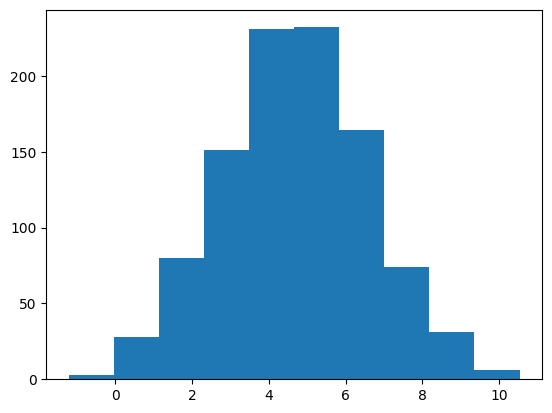

In [4]:
_ =plt.hist(researh_0["condition_after_1"])

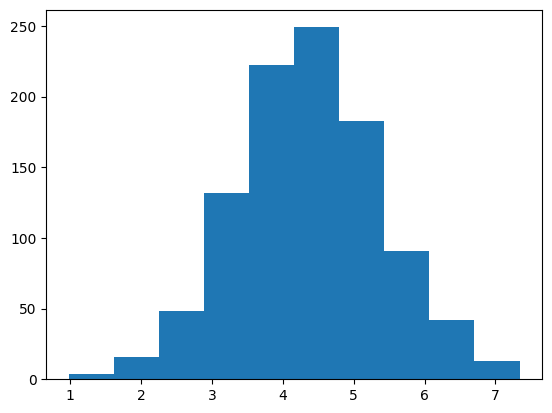

In [5]:
_ =plt.hist(researh_0["condition_after_10"])

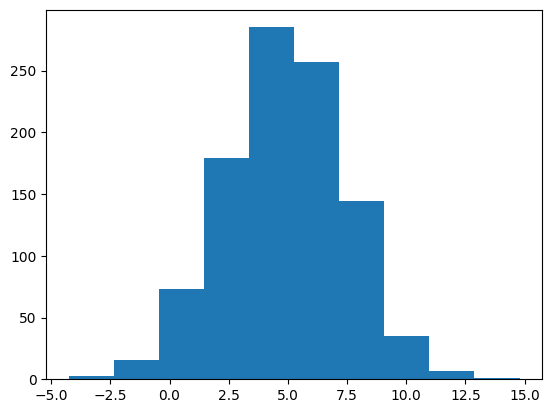

In [6]:
_ =plt.hist(researh_0["condition_after_100"])

# Задание

Мы хотим:
- проверить, что с данными все в порядке (т.к. данные генерили с помощью распределений, у нас могут быть отрицательные числа, которые надо исправить на 0, а также числа больше 10, которые надо исправить на 10) - построить гистограммы и почистить данные
- сравнить между собой результаты исследований разных вакцин и каким-либо образом представить сравнение исследований (т.е., к примеру, показать в одном пространстве сразу 3 исследования, пользуясь признаками "средняя оценка самочувствия после 1 часа", "средняя оценка самочувствия после 10 часов", "средняя оценка самочувствия после 100 часов"
- важно! обратите внимание на цвета, что вы используете

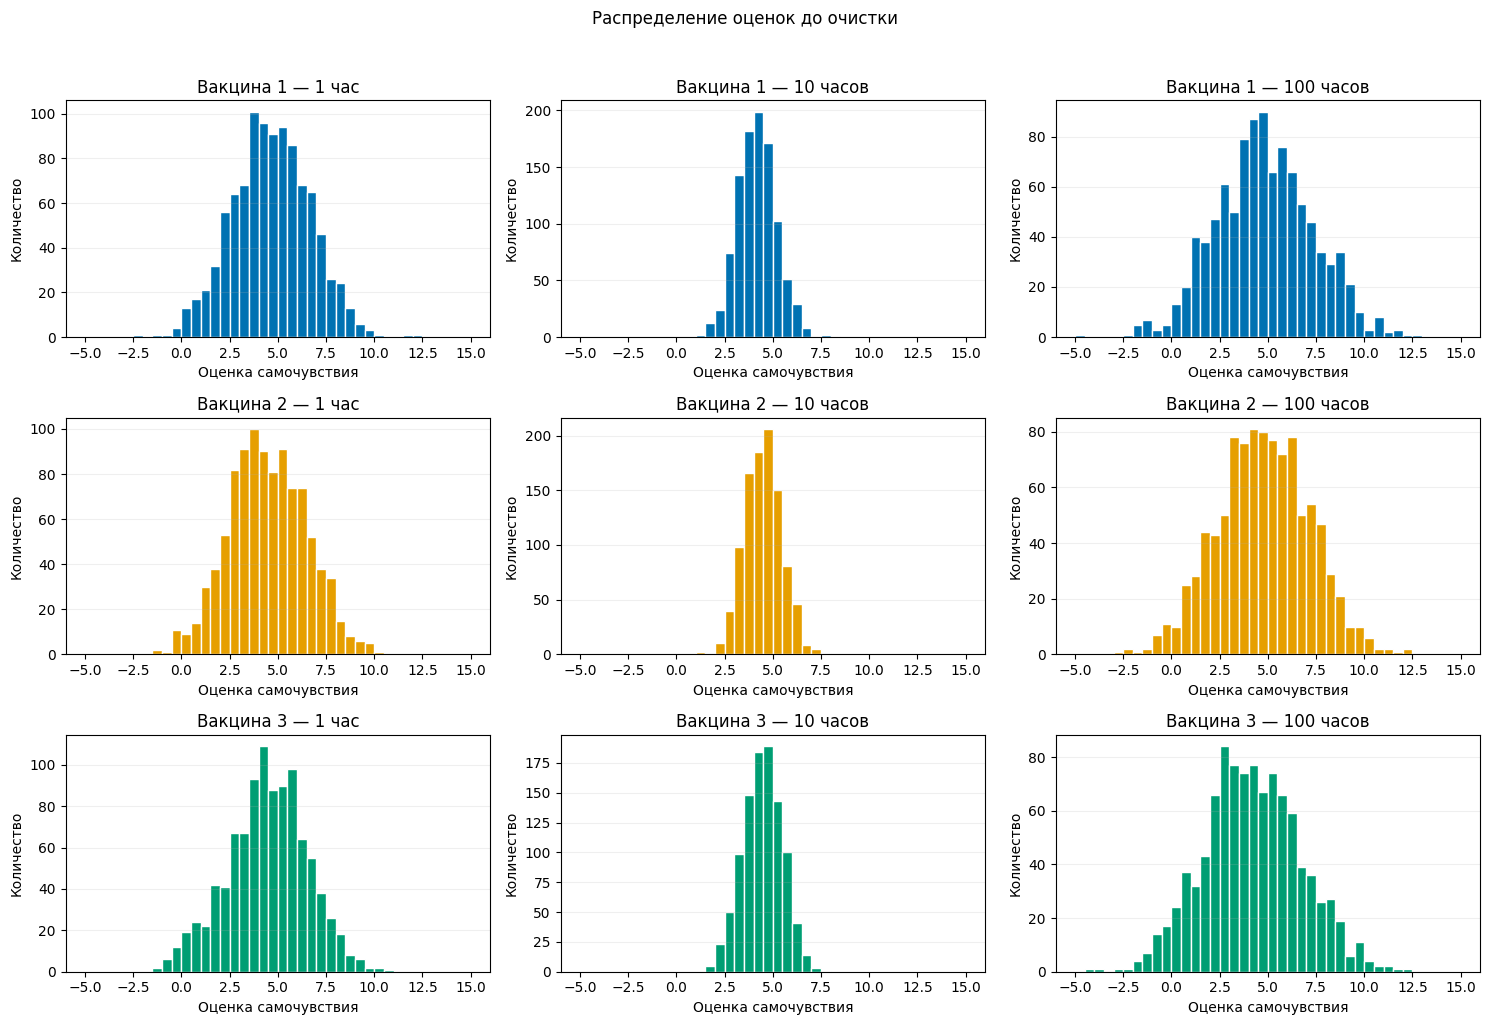

In [ ]:

researh_0 = make_research()
researh_1 = make_research()
researh_2 = make_research()

researches = {
    "Вакцина 1": researh_0,
    "Вакцина 2": researh_1,
    "Вакцина 3": researh_2
}

colors = ["#0072B2", "#E69F00", "#009E73"]

columns = [
    "condition_after_1",
    "condition_after_10",
    "condition_after_100"
]

labels = ["1 час", "10 часов", "100 часов"]


fig, axes = plt.subplots(3, 3, figsize=(15, 10))

for i, (name, research) in enumerate(researches.items()):
    for j, column in enumerate(columns):
        axes[i, j].hist(
            research[column],
            bins=np.linspace(-5, 15, 41),
            color=colors[i],
            edgecolor="white"
        )

        axes[i, j].set_title(f"{name} — {labels[j]}")
        axes[i, j].set_xlabel("Оценка самочувствия")
        axes[i, j].set_ylabel("Количество")
        axes[i, j].grid(axis="y", alpha=0.2)

plt.suptitle("Распределение оценок до очистки", y=1.02)
plt.tight_layout()
plt.show()


In [ ]:


for name, research in researches.items():
    print(f"\n{name}")

    for column, label in zip(columns, labels):
        values = research[column]

        below_zero = np.sum(values < 0)
        above_ten = np.sum(values > 10)

        print(
            f"{label}: меньше 0 — {below_zero}, "
            f"больше 10 — {above_ten}"
        )


for research in researches.values():
    for column in columns:
        research[column] = np.clip(
            research[column], 0, 10
        )



Вакцина 1
1 час: меньше 0 — 7, больше 10 — 3
10 часов: меньше 0 — 0, больше 10 — 0
100 часов: меньше 0 — 22, больше 10 — 18

Вакцина 2
1 час: меньше 0 — 14, больше 10 — 1
10 часов: меньше 0 — 0, больше 10 — 0
100 часов: меньше 0 — 24, больше 10 — 13

Вакцина 3
1 час: меньше 0 — 20, больше 10 — 3
10 часов: меньше 0 — 0, больше 10 — 0
100 часов: меньше 0 — 46, больше 10 — 10


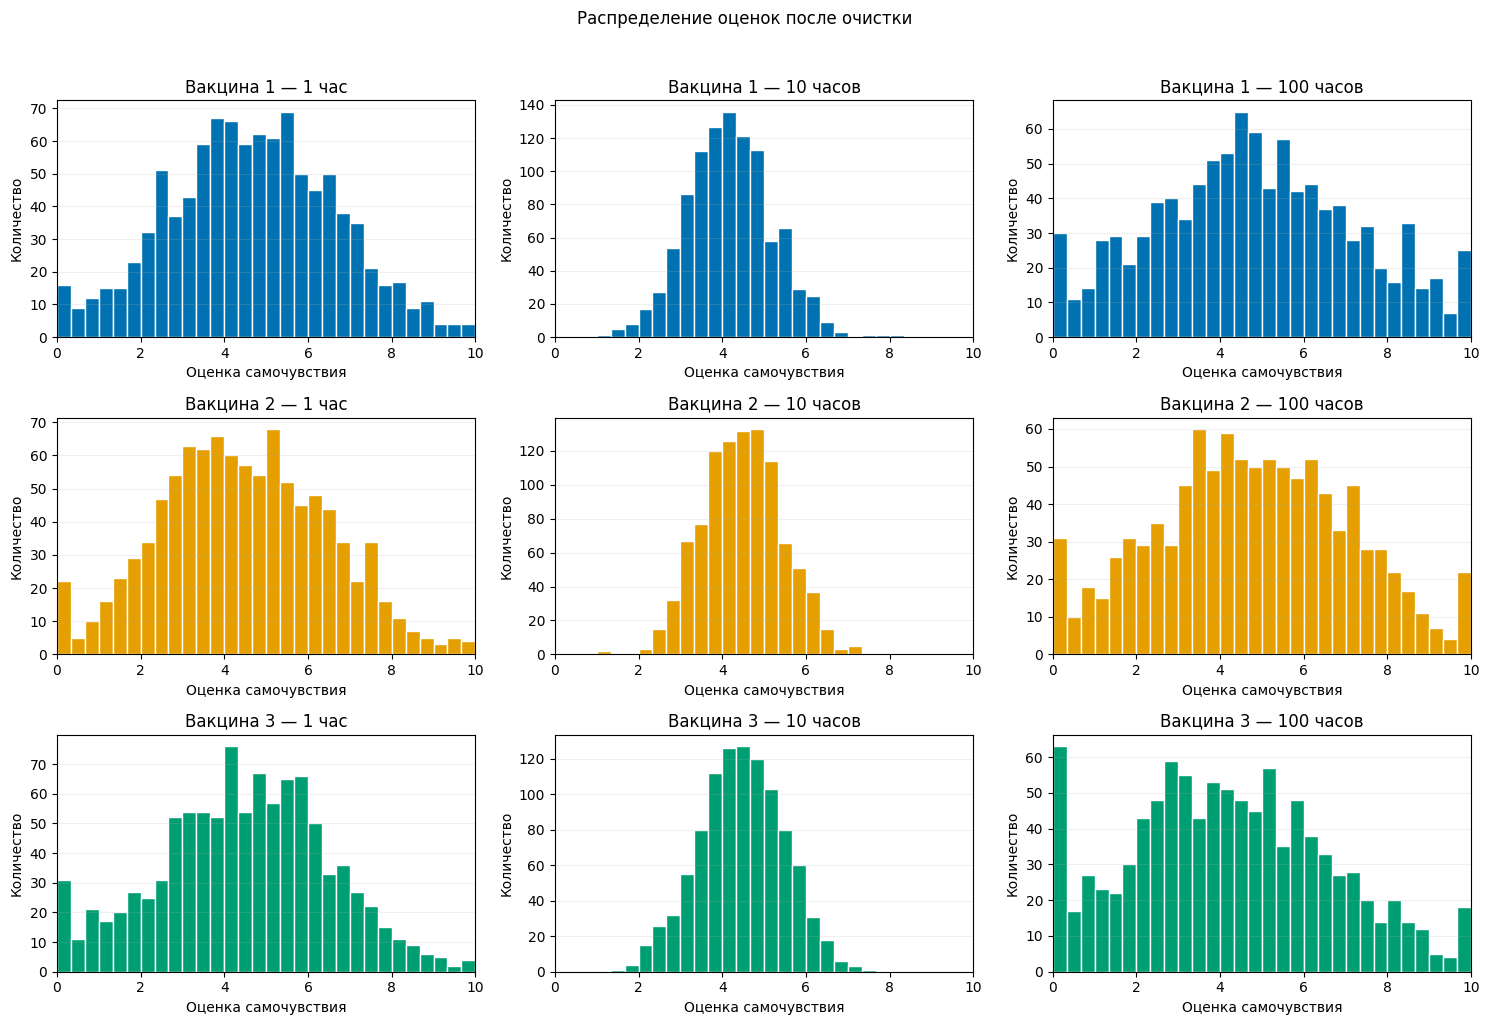

In [20]:

fig, axes = plt.subplots(3, 3, figsize=(15, 10))

for i, (name, research) in enumerate(researches.items()):
    for j, column in enumerate(columns):
        axes[i, j].hist(
            research[column],
            bins=np.linspace(0, 10, 31),
            color=colors[i],
            edgecolor="white"
        )

        axes[i, j].set_title(f"{name} — {labels[j]}")
        axes[i, j].set_xlabel("Оценка самочувствия")
        axes[i, j].set_ylabel("Количество")
        axes[i, j].set_xlim(0, 10)
        axes[i, j].grid(axis="y", alpha=0.2)

plt.suptitle("Распределение оценок после очистки", y=1.02)
plt.tight_layout()
plt.show()


Вакцина 1 [4.65, 4.18, 4.82]
Вакцина 2 [4.46, 4.48, 4.77]
Вакцина 3 [4.45, 4.45, 4.21]


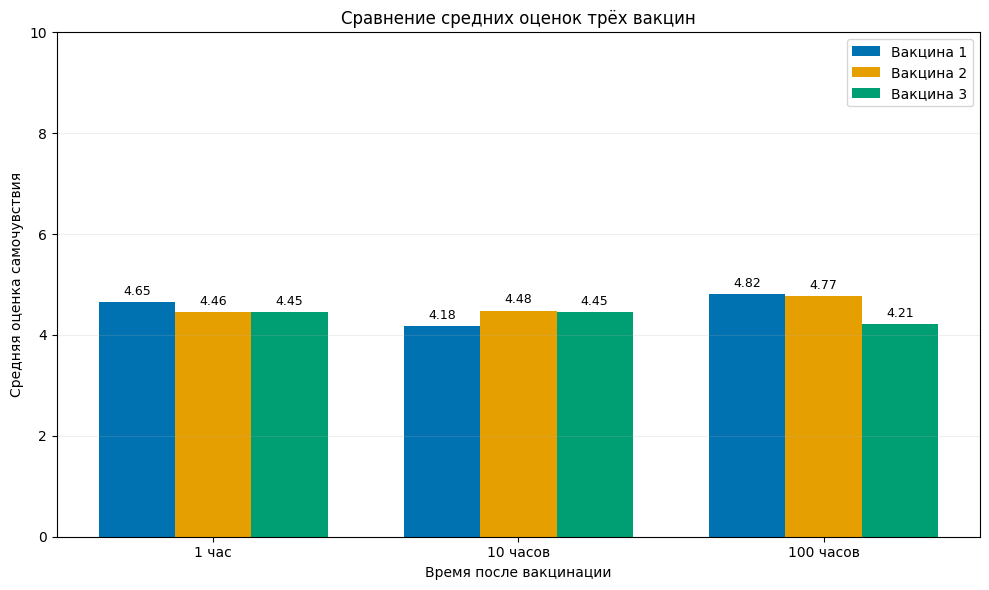

In [21]:

means = {}

for name, research in researches.items():
    means[name] = [
        research[column].mean() for column in columns
    ]

for name, values in means.items():
    print(name, [round(float(value), 2) for value in values])

x = np.arange(3)
width = 0.25

fig, ax = plt.subplots(figsize=(10, 6))

for i, (name, values) in enumerate(means.items()):
    bars = ax.bar(
        x + (i - 1) * width,
        values,
        width,
        label=name,
        color=colors[i]
    )

    ax.bar_label(bars, fmt="%.2f", padding=3, fontsize=9)

ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylabel("Средняя оценка самочувствия")
ax.set_xlabel("Время после вакцинации")
ax.set_title("Сравнение средних оценок трёх вакцин")
ax.set_ylim(0, 10)
ax.legend()
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()


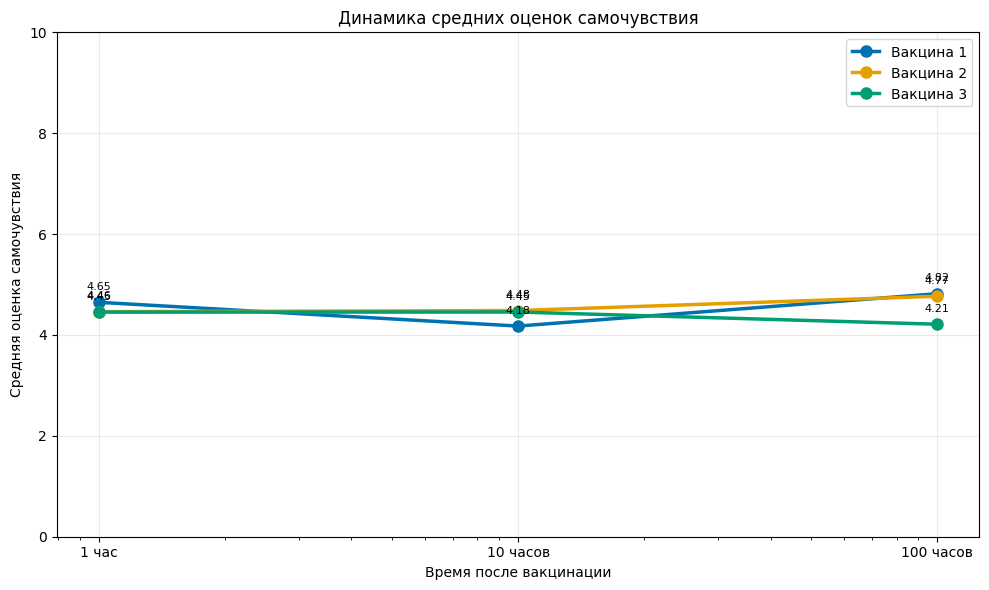

In [22]:

fig, ax = plt.subplots(figsize=(10, 6))

hours = [1, 10, 100]

for i, (name, values) in enumerate(means.items()):
    ax.plot(
        hours,
        values,
        marker="o",
        markersize=8,
        linewidth=2.5,
        color=colors[i],
        label=name
    )

    for hour, value in zip(hours, values):
        ax.annotate(
            f"{value:.2f}",
            (hour, value),
            textcoords="offset points",
            xytext=(0, 9),
            ha="center",
            fontsize=8
        )

ax.set_xscale("log")
ax.set_xticks(hours)
ax.set_xticklabels(labels)

ax.set_ylim(0, 10)
ax.set_xlabel("Время после вакцинации")
ax.set_ylabel("Средняя оценка самочувствия")
ax.set_title("Динамика средних оценок самочувствия")

ax.grid(True, alpha=0.25)
ax.legend()

plt.tight_layout()
plt.show()


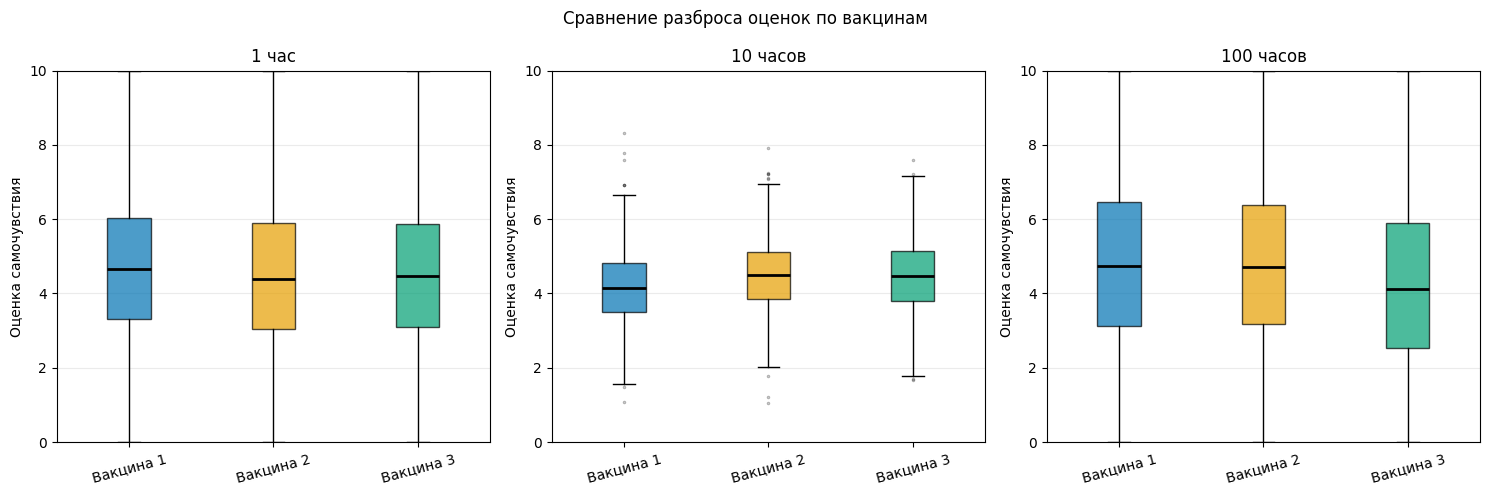

In [23]:

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for j, column in enumerate(columns):
    data = [
        research[column]
        for research in researches.values()
    ]

    box = axes[j].boxplot(
        data,
        patch_artist=True,
        tick_labels=list(researches.keys()),
        medianprops={"color": "black", "linewidth": 2},
        flierprops={
            "marker": ".",
            "markersize": 3,
            "alpha": 0.3
        }
    )

    for patch, color in zip(box["boxes"], colors):
        patch.set_facecolor(color)
        patch.set_alpha(0.7)

    axes[j].set_title(labels[j])
    axes[j].set_ylabel("Оценка самочувствия")
    axes[j].set_ylim(0, 10)
    axes[j].grid(axis="y", alpha=0.25)
    axes[j].tick_params(axis="x", rotation=15)

fig.suptitle("Сравнение разброса оценок по вакцинам")
plt.tight_layout()
plt.show()


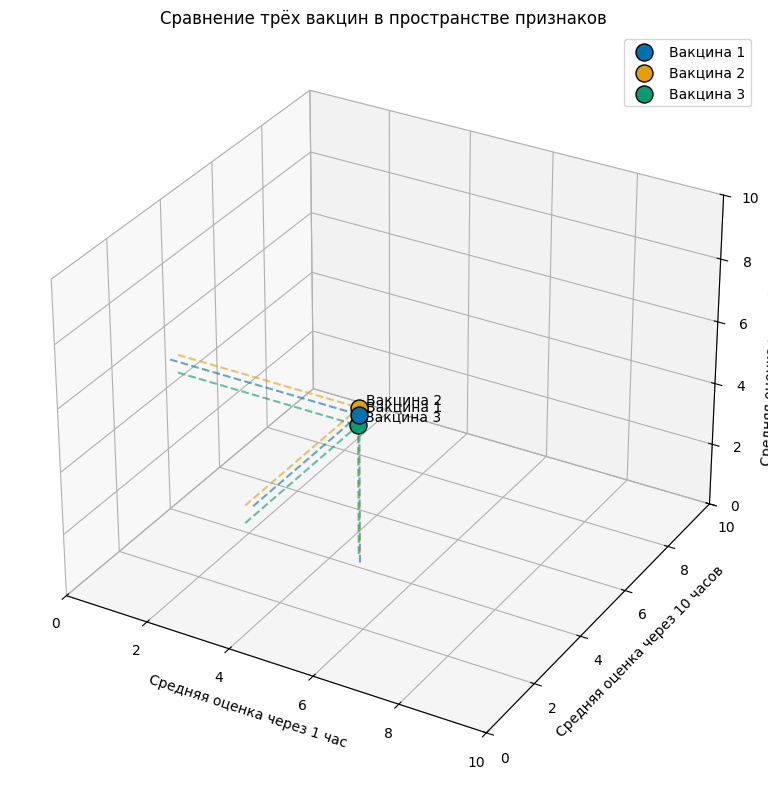

In [ ]:


fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection="3d")

for i, (name, values) in enumerate(means.items()):
    ax.scatter(
        values[0],
        values[1],
        values[2],
        color=colors[i],
        s=150,
        edgecolor="black",
        label=name
    )

    ax.plot(
        [values[0], values[0]],
        [values[1], values[1]],
        [0, values[2]],
        "--",
        color=colors[i],
        alpha=0.6
    )

    ax.plot(
        [values[0], values[0]], [0, values[1]],
        [values[2], values[2]],
        "--", color=colors[i], alpha=0.6
    )

    ax.plot(
        [0, values[0]], [values[1], values[1]],
        [values[2], values[2]],
        "--", color=colors[i], alpha=0.6
    )

    ax.text(
        values[0] + 0.1,
        values[1] + 0.1,
        values[2] + 0.1,
        name,
        fontsize=10
    )

ax.set_xlabel("Средняя оценка через 1 час")
ax.set_ylabel("Средняя оценка через 10 часов")
ax.set_zlabel("Средняя оценка через 100 часов")

ax.set_title("Сравнение трёх вакцин в пространстве признаков")

ax.set_xlim(0, 10)
ax.set_ylim(0, 10)
ax.set_zlim(0, 10)

ax.legend()
ax.grid(True)

plt.tight_layout()
plt.show()